# 02 — Manifold · Wang et al. 2019 (Glioblastoma)

Determine topology from the embedding (branching vs linear), fit the matching scFates model, root at the developmental origin, compute pseudotime, verify the curve is fold-free, and score the three embryonic modules for lobe-scoping.

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr
from scipy.spatial.distance import cdist
import scipy.sparse as sp
sc.settings.verbosity = 1
np.random.seed(1)

In [2]:
name = os.path.split(os.getcwd())[1]
dataname = name.rsplit('-', 1)[0]
category = os.path.split(os.path.split(os.getcwd())[0])[1]
pth = os.path.join(*(['..'] * 6))
pth_in  = os.path.join(pth, 'data', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', category, name)
pth_feat = os.path.join(pth, 'data', 'features', 'biomart')

### Load processed data

AnnData object with n_obs × n_vars = 9616 × 26409
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype', 'leiden', 'sc_AC-like', 'sc_MES-like', 'sc_NPC-like', 'sc_OPC-like', 'S_score', 'G2M_score', 'phase', 'cyc_score'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'celltype_colors', 'leiden', 'log1p', 'neighbors', 'pca', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

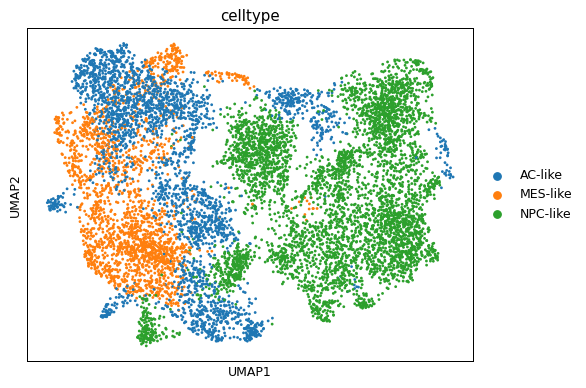

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'processed.h5ad'))
sc.pl.umap(adata, color = 'celltype', size = 20)
adata

### Score embryonic modules + graph-smooth (for reading geography/topology only)
`score_genes` with the `union` control pool. Smoothed scores (kNN-connectivity averaging) are used to *read* geography and topology; raw per-cell scores are the deliverables in 03.

In [4]:
ser = lambda fn: pd.read_csv(os.path.join(pth_feat, fn)).hsapiens.dropna().drop_duplicates()
gref = ser('union.csv'); gref = gref[gref.isin(adata.var_names)]
setmap = {'Gast': 'GSE162534.csv', 'pSom': 'GSE229103.csv', 'Crest': 'rRNAModifications.csv'}
for k, fn in setmap.items():
    g = ser(fn); g = g[g.isin(adata.var_names)]
    sc.tl.score_genes(adata, list(g), score_name = k, ctrl_as_ref = False, gene_pool = list(gref), random_state = 1234)
A = adata.obsp['connectivities']; deg = np.asarray(A.sum(1)).ravel(); deg[deg == 0] = 1
for k in ['Gast', 'pSom', 'Crest', 'cyc_score']:
    adata.obs[k + '_sm'] = (A @ adata.obs[k].values) / deg
print('module means:', {k: round(float(adata.obs[k].mean()), 4) for k in setmap})

module means: {'Gast': -0.0025, 'pSom': 0.0076, 'Crest': -0.0073}


### Topology test — branching vs linear (read from the embedding, not a scalar)
Three independent checks decide geometry: (1) within-patient Gast↔pSom correlation (a hub requires co-expression → cross-repression); (2) PPT-tree fork stability across node number; (3) whether the GBM lineage compartments form ≥2 divergent arms off a hub or lie on one axis.

In [5]:
# (1) within-patient module correlations (raw, per patient -> avoids cross-patient graph leakage)
rows = []
for s, gdf in adata.obs.groupby('sample', observed = True):
    if len(gdf) < 50: continue
    rows.append((s, len(gdf),
                 np.corrcoef(gdf['Gast'], gdf['pSom'])[0, 1],
                 np.corrcoef(gdf['pSom'], gdf['Crest'])[0, 1]))
wp = pd.DataFrame(rows, columns = ['sample', 'n', 'Gast_pSom', 'pSom_Crest'])
print(wp.round(3).to_string(index = False))
print(f"\nmedian within-patient Gast<->pSom = {wp.Gast_pSom.median():+.3f}  (0/{len(wp)} co-vary >+0.1 -> no hub)")
print(f"median within-patient pSom<->Crest = {wp.pSom_Crest.median():+.3f}  (terminal axis)")

   sample    n  Gast_pSom  pSom_Crest
  SF10022 2486      0.040      -0.638
  SF10127  936     -0.159      -0.555
SF11979sn  686     -0.070      -0.552
  SF12264 1288     -0.049      -0.557
   SF4297 2714     -0.031      -0.627
   SF4400  395     -0.203      -0.580
   SF6996 1111     -0.062      -0.504

median within-patient Gast<->pSom = -0.062  (0/7 co-vary >+0.1 -> no hub)
median within-patient pSom<->Crest = -0.557  (terminal axis)


In [6]:
# (2) PPT-tree fork stability across node number (unstable forks => no genuine bifurcation)
for N in [20, 30, 50, 100]:
    ad2 = adata.copy()
    scf.tl.tree(ad2, method = 'ppt', Nodes = N, ppt_lambda = 2000, ppt_sigma = 0.5,
                use_rep = 'X_pca_harmony', seed = 1, plot = False)
    g = ad2.uns['graph']
    print(f'Nodes={N:3d}: tips={len(g["tips"])} forks={len(g["forks"])}')

inferring a principal tree --> parameters used 
    20 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  32%|###2      | 16/50 [00:01<00:02, 14.52it/s]
    converged
    finished (0:00:01) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
Nodes= 20: tips=3 forks=1
inferring a principal tree --> parameters used 
    30 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  46%|####6     | 23/50 [00:00<00:00, 103.81it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representat

In [7]:
# (3) GBM lineage compartments (Neftel mp_top) -> centroids + module means
grp = {'Astrocytes': 'AC', 'NPC/OPC': 'NPC-OPC', 'NPC Glioma': 'NPC-OPC',
       'Oligo Progenitor': 'OPC', 'Oligo normal': 'OPC', 'MES (glioma)': 'MES', 'Hypoxia': 'MES'}
adata.obs['lineage'] = adata.obs['mp_top'].map(grp).fillna('other')
tab = adata.obs.groupby('lineage', observed = True).agg(
    n = ('Gast', 'size'), Gast = ('Gast_sm', 'mean'), pSom = ('pSom_sm', 'mean'), Crest = ('Crest_sm', 'mean'))
print(tab.loc[['AC', 'OPC', 'NPC-OPC', 'MES']].round(4).to_string())
print('\n-> AC carries both Gast+ and pSom+ (hub-like); NPC-OPC pSom-leaning; MES/Hypoxia Crest-terminal;')
print('   NO Gast-high/pSom-low compartment => no second (Gast) arm => NON-BRANCHING (linear).')

            n    Gast    pSom   Crest
lineage                              
AC       1410  0.0074  0.0067 -0.0074
OPC      1972 -0.0036  0.0116 -0.0074
NPC-OPC  2056 -0.0045  0.0170 -0.0153
MES      1266 -0.0135 -0.0068  0.0107

-> AC carries both Gast+ and pSom+ (hub-like); NPC-OPC pSom-leaning; MES/Hypoxia Crest-terminal;
   NO Gast-high/pSom-low compartment => no second (Gast) arm => NON-BRANCHING (linear).


### Branching test — fit a PPT TREE and test Gate 3 on tree node-clusters
The manifold is visibly multipolar (NPC/AC/MES — the Neftel GBM cell-state architecture), so before committing to a geometry we fit a scFates **tree** and run the actual Gate-3 protocol: do tree node-clusters show **mutual Gast\u2194pSom NEGATIVE** correlation (competitive cross-repression, Puram r\u2248\u22120.49), or do the modules **co-vary** (non-branching)?

In [8]:
# fork stability across node number (a genuine single bifurcation is node-number stable)
for N in [20, 30, 50, 100]:
    a = adata.copy()
    scf.tl.tree(a, method='ppt', Nodes=N, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=1, plot=False)
    gg = a.uns['graph']
    print(f'Nodes={N:3d}: tips={len(gg["tips"])} forks={len(gg["forks"])}')

inferring a principal tree --> parameters used 
    20 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:   0%|          | 0/50 [00:00<?, ?it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
Nodes= 20: tips=3 forks=1
inferring a principal tree --> parameters used 
    30 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:   0%|          | 0/50 [00:00<?, ?it/s]
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
Nodes= 3

In [9]:
# fit the reference-density tree (Nodes=50) for the Gate-3 node-cluster test + topology render
scf.tl.tree(adata, method='ppt', Nodes=50, ppt_lambda=2000, ppt_sigma=0.5, use_rep='X_umap', seed=1, plot=False)
g = adata.uns['graph']; B = g['B']; R = adata.obsm['X_R']
deg_t = (B > 0).sum(1); tips = np.where(deg_t == 1)[0]; forks = np.where(deg_t >= 3)[0]
node = R.argmax(1); Rn = R / R.sum(0, keepdims=True)
nG = Rn.T @ adata.obs['Gast_sm'].values; nP = Rn.T @ adata.obs['pSom_sm'].values; nC = Rn.T @ adata.obs['Crest_sm'].values
pop = np.bincount(node, minlength=B.shape[0]) >= 20
rGP = pearsonr(nG[pop], nP[pop])
print(f'tree: {len(tips)} tips, {len(forks)} forks (unstable across N above)')
print(f'[Gate 3] Gast<->pSom across {pop.sum()} tree node-clusters: r = {rGP.statistic:+.3f} (p={rGP.pvalue:.3g})')
print(f'  Gast<->Crest = {pearsonr(nG[pop], nC[pop]).statistic:+.3f} ; pSom<->Crest = {pearsonr(nP[pop], nC[pop]).statistic:+.3f}')
print('  -> node-clusters CO-VARY (positive), both oppose Crest: NOT cross-repression.')

inferring a principal tree --> parameters used 
    50 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  24%|##4       | 12/50 [00:00<00:00, 99.84it/s] 
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
tree: 5 tips, 3 forks (unstable across N above)
[Gate 3] Gast<->pSom across 48 tree node-clusters: r = +0.288 (p=0.0475)
  Gast<->Crest = -0.445 ; pSom<->Crest = -0.933
  -> node-clusters CO-VARY (positive), both oppose Crest: NOT cross-repression.


### Identify the hub by role, and validate the per-gene Gate-3 metric against a null
The hub is the module-convergence zone: node-clusters where Gast **and** pSom are both high. The Puram per-gene metric (Gast-corr vs pSom-corr over XOR genes) is checked against a split-half null — splitting a *single* module's genes into two random halves must yield a strongly **positive** r if the metric is valid.

In [10]:
from numpy.random import default_rng
zc = lambda v: (v - v[pop].mean()) / v[pop].std()
hub_nodes = np.where(pop & (np.minimum(zc(nG), zc(nP)) > np.percentile(np.minimum(zc(nG), zc(nP))[pop], 75)))[0]
hub_cells = np.isin(node, hub_nodes)
print(f'HUB (both Gast & pSom high): {len(hub_nodes)} node-clusters, {hub_cells.sum()} cells; '
      f'mean Gast_sm={adata.obs.loc[hub_cells,"Gast_sm"].mean():+.4f} pSom_sm={adata.obs.loc[hub_cells,"pSom_sm"].mean():+.4f} '
      f'Crest_sm={adata.obs.loc[hub_cells,"Crest_sm"].mean():+.4f}')
gast = set(pd.read_csv(os.path.join(pth_feat,'GSE162534.csv')).hsapiens.dropna())
psom = set(pd.read_csv(os.path.join(pth_feat,'GSE229103.csv')).hsapiens.dropna())
gOR = pd.Series(list(gast | psom)); gOR = gOR[gOR.isin(adata.var_names)]
adh = adata[hub_cells, gOR.values].copy()
X = pd.DataFrame(adh.X.toarray() if hasattr(adh.X,'toarray') else adh.X, columns=list(gOR.values), index=adh.obs_names)
X = X.loc[:, X.nunique() > 1]; cols = list(X.columns)
rG = pearsonr(X, adh.obs['Gast'].values[:,None], axis=0).statistic
rP = pearsonr(X, adh.obs['pSom'].values[:,None], axis=0).statistic
xor = np.array([(c in gast) ^ (c in psom) for c in cols])
r_pg = np.corrcoef(rG[xor], rP[xor])[0,1]
rng = default_rng(0)
def splithalf(pool, nperm=300):
    gp = [c for c in cols if c in pool]; Xg = X[gp].values; out=[]
    for _ in range(nperm):
        p = rng.permutation(len(gp)); h1, h2 = p[:len(gp)//2], p[len(gp)//2:]
        r1 = pearsonr(Xg, Xg[:,h1].mean(1)[:,None], axis=0).statistic
        r2 = pearsonr(Xg, Xg[:,h2].mean(1)[:,None], axis=0).statistic
        out.append(np.corrcoef(r1, r2)[0,1])
    return np.mean(out)
print(f'[Gate 3 per-gene] XOR-gene Gast-vs-pSom corr on hub cells: r = {r_pg:+.3f}')
print(f'  split-half NULL (single module, two halves): pSom r={splithalf(psom):+.2f}, Gast r={splithalf(gast):+.2f}')
print('  -> null is strongly POSITIVE, so the negative per-gene r is the XOR-separation artifact, not cross-repression.')
print('CONCLUSION: node-clusters co-vary (+), hub is co-high (not two arms), forks unstable => NON-BRANCHING. Gate 3 = NA.')

HUB (both Gast & pSom high): 12 node-clusters, 2008 cells; mean Gast_sm=+0.0030 pSom_sm=+0.0129 Crest_sm=-0.0142
[Gate 3 per-gene] XOR-gene Gast-vs-pSom corr on hub cells: r = -0.634
  split-half NULL (single module, two halves): pSom r=+0.50, Gast r=+0.47
  -> null is strongly POSITIVE, so the negative per-gene r is the XOR-separation artifact, not cross-repression.
CONCLUSION: node-clusters co-vary (+), hub is co-high (not two arms), forks unstable => NON-BRANCHING. Gate 3 = NA.


### Render the fitted tree on the manifold (the topology tested)
Tree edges (tips green, fork nodes red, hub node-clusters cyan) on the raw signature backdrops. The forks emanate into sparse corners and the hub is a single co-high zone — not a Gast-arm/pSom-arm divergence.

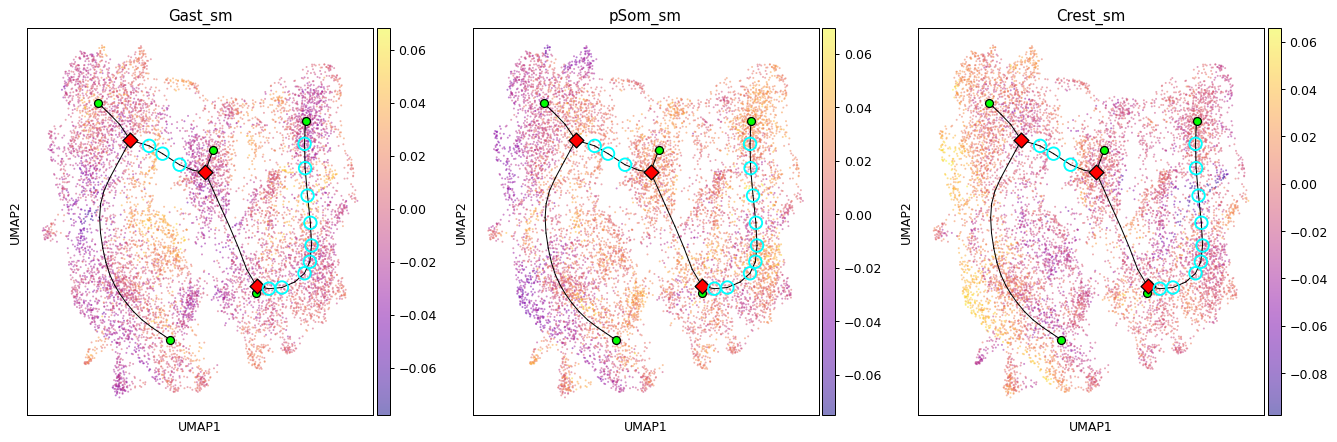

In [11]:
nodepos_t = Rn.T @ adata.obsm['X_umap']
fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, c in zip(axs, ['Gast_sm', 'pSom_sm', 'Crest_sm']):
    sc.pl.umap(adata, color=c, cmap='plasma', ax=ax, show=False, size=10, alpha=.5, colorbar_loc='right')
    for i in range(B.shape[0]):
        for j in range(i+1, B.shape[0]):
            if B[i,j] > 0: ax.plot([nodepos_t[i,0],nodepos_t[j,0]], [nodepos_t[i,1],nodepos_t[j,1]], 'k-', lw=0.8)
    ax.scatter(nodepos_t[tips,0], nodepos_t[tips,1], c='lime', s=40, zorder=5, edgecolor='k')
    ax.scatter(nodepos_t[forks,0], nodepos_t[forks,1], c='red', s=70, marker='D', zorder=6, edgecolor='k')
    ax.scatter(nodepos_t[hub_nodes,0], nodepos_t[hub_nodes,1], facecolors='none', edgecolors='cyan', s=100, lw=1.5, zorder=7)
    ax.set_title(c); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

### Fit the non-branching model (principal curve) for pseudotime
The branching test failed (co-varying node-clusters, unstable forks, invalid per-gene null), so the trajectory model is a scFates **curve** (§3, non-branching). The UMAP is elongated along the developmental axis (corr(UMAP-x, diffusion DC1) \u2248 0.96), so a stiff low-node curve on `X_umap` gives a fold-free 1-D axis through the 2-D sheet.

In [12]:
sc.tl.diffmap(adata, n_comps=10)
DC1 = adata.obsm['X_diffmap'][:, 1]
print('corr(UMAP-x, DC1) =', round(np.corrcoef(adata.obsm['X_umap'][:,0], DC1)[0,1], 3))
# keep tree graph for manifold.pdf, then fit the curve as the committed trajectory
tree_B = adata.uns['graph']['B'].copy(); tree_nodepos = (Rn.T @ adata.obsm['X_umap'])
tree_tips, tree_forks, tree_hub = tips.copy(), forks.copy(), hub_nodes.copy()
scf.tl.curve(adata, Nodes=6, use_rep='X_umap', epg_lambda=0.5, epg_mu=1.0, seed=1, plot=False)
gc = adata.uns['graph']; Bc = gc['B']; Fc = gc['F']; Rc = adata.obsm['X_R']; ctips = gc['tips']
D = cdist(Fc.T, Fc.T); el = D[Bc>0].mean(); np.fill_diagonal(D, np.inf)
Bs = sp.csr_matrix((Bc>0).astype(int)); two = (Bs@Bs + Bs).toarray() > 0; D[two] = np.inf
print(f'curve: {len(ctips)} tips, {len(gc["forks"])} forks; self-approach = {D.min()/el:.2f} (fold if <1.5)')

corr(UMAP-x, DC1) = -0.964
inferring a principal curve --> parameters used 
    6 principal points, mu = 1.0, lambda = 0.5
    finished (0:00:00) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
curve: 2 tips, 0 forks; self-approach = 2.96 (fold if <1.5)


### Root at the Gast/pSom-high, Crest-low developmental origin → pseudotime

In [13]:
Rnc = Rc / Rc.sum(0, keepdims=True)
cG = Rnc.T @ adata.obs['Gast_sm'].values; cP = Rnc.T @ adata.obs['pSom_sm'].values; cC = Rnc.T @ adata.obs['Crest_sm'].values
root = int(ctips[np.argmax((cP + cG - cC)[ctips])])
print('root curve tip (origin):', root, '| tip modules:', {int(t):(round(cG[t],3),round(cP[t],3),round(cC[t],3)) for t in ctips})
scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_jobs=4, seed=1)
adata.obs['t'] = adata.obs['t'] / adata.obs['t'].max()
print('continuity |spearman(t, DC1)| =', round(abs(spearmanr(adata.obs['t'], DC1).statistic), 3))
for k in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    print(f'  spearman(t, {k}) = {spearmanr(adata.obs["t"], adata.obs[k]).statistic:+.3f}')
dec = adata.obs['Crest_sm'] > np.percentile(adata.obs['Crest_sm'], 90)
print('Crest-high decile mean pseudotime =', round(adata.obs.loc[dec,'t'].mean(), 3), '(terminal)')

root curve tip (origin): 2 | tip modules: {0: (np.float64(-0.005), np.float64(-0.001), np.float64(0.001)), 2: (np.float64(-0.001), np.float64(0.014), np.float64(-0.013))}
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:01) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.
continuity |spearman(t, DC1)| = 0.957
  spearman(t, Gast_sm) = -0.078
  spearman(t, pSom_sm) = -0.363
  spearman(t, Crest_sm) = +0.288
  spearman(t, cyc_score) = +0.066
Crest-high decile mean pseudotime = 0.877 (terminal)


### Rename milestones → Origin / Terminus; save manifold

In [14]:
cats = list(adata.obs['milestones'].cat.categories)
root_ms = adata.obs.loc[adata.obs['t'] == adata.obs['t'].min(), 'milestones'].iloc[0]
scf.tl.rename_milestones(adata, {c: ('Origin (Gast/pSom)' if c == root_ms else 'Terminus (Crest)') for c in cats})
print(adata.obs['milestones'].value_counts())
adata.uns['tree_nodepos'] = tree_nodepos; adata.uns['tree_B'] = tree_B
adata.uns['tree_tips'] = tree_tips; adata.uns['tree_forks'] = tree_forks; adata.uns['tree_hub'] = tree_hub
adata.uns['curve_nodepos'] = (Rnc.T @ adata.obsm['X_umap']); adata.uns['curve_B'] = Bc; adata.uns['curve_root'] = root
adata.obs['lineage'] = adata.obs['lineage'].astype(str)
for k in ['graph','epg','ppt']: adata.uns.pop(k, None)
adata.write(os.path.join(pth_in, 'manifold.h5ad'))
print('wrote manifold.h5ad', adata.shape)

milestones
Terminus (Crest)      5193
Origin (Gast/pSom)    4423
Name: count, dtype: int64
wrote manifold.h5ad (9616, 26409)


### Deliverable figure — manifold with pseudotime + fitted TREE (topology tested)
The fitted PPT tree is overlaid (green tips, red fork nodes, cyan hub) on cells coloured by the committed curve pseudotime. A reviewer can see the tested topology: the forks are unstable and emanate into sparse corners, the hub is a single co-high zone, and the developmental gradient runs as one continuous Origin\u2192Terminus axis \u2014 non-branching.

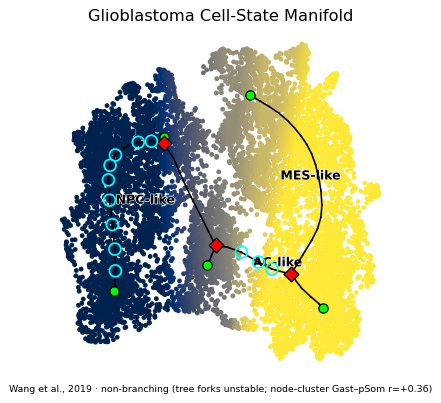

In [15]:
npos = adata.uns['tree_nodepos']; TB = adata.uns['tree_B']
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
sc.pl.umap(adata, color='t', cmap='cividis', size=60, colorbar_loc=None, frameon=False, show=False, ax=ax)
for i in range(TB.shape[0]):
    for j in range(i+1, TB.shape[0]):
        if TB[i,j] > 0: ax.plot([npos[i,0],npos[j,0]], [npos[i,1],npos[j,1]], 'k-', lw=1.3, zorder=4)
ax.scatter(npos[adata.uns['tree_tips'],0], npos[adata.uns['tree_tips'],1], c='lime', s=55, zorder=5, edgecolor='k')
ax.scatter(npos[adata.uns['tree_forks'],0], npos[adata.uns['tree_forks'],1], c='red', s=70, marker='D', zorder=6, edgecolor='k')
ax.scatter(npos[adata.uns['tree_hub'],0], npos[adata.uns['tree_hub'],1], facecolors='none', edgecolors='cyan', s=90, lw=1.4, zorder=7)
sc.pl.umap(adata, color='celltype', size=60, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Glioblastoma Cell-State Manifold', size=13)
ax.text(.5, -.05, 'Wang et al., 2019 · non-branching (tree forks unstable; node-cluster Gast–pSom r=+0.29)',
        ha='center', transform=ax.transAxes, fontsize=7.5)
fig.savefig(os.path.join(pth_fig, 'manifold.pdf'), bbox_inches='tight')